# t-SNE versus UMAP

- **Purpose:** Compare t-SNE and UMAP for the Leiden-subpopulation view.
- **Inputs:** Shared artifact `../4_biological_plausibility/adata_config10_joint/config10_joint_3k.h5ad`.
- **Outputs:** Side-by-side embeddings shown in the notebook.
- **Result:** The t-SNE view was rejected; UMAP is retained for the final figures.


In [1]:
from pathlib import Path
import scanpy as sc
import anndata as ad

INPUT = Path.cwd().parent / "4_biological_plausibility" / "adata_config10_joint" / "config10_joint_3k.h5ad"
adata = ad.read_h5ad(INPUT)

settings = adata.uns["bio_leiden_settings"]
t_key = f"tumor_leiden_res{float(settings['tumor_res'])}"
f_key = f"full_leiden_res{float(settings['full_res'])}"

color = ["batch", t_key, f_key, "label"]
adata

AnnData object with n_obs × n_vars = 110293 × 28617
    obs: 'cell_id', 'cell_line', 'chemistry', 'mmr_status', 'batch', 'dataset', 'label', 'donor_id', 'biosample_id', 'mlh1_status', 'sex', 'tissue_site', 'pathological_stage', 'tumor_grade', 'TissueSource', 'ProcessingMethod', 'TumorStage', 'LymphNodeStatus', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'tumor_leiden_res0.9', 'full_leiden_res1.0'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'hvg'
    uns: 'bio_leiden_settings', 'log1p', 'neighbors', 'umap'
    obsm: 'X_latent', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

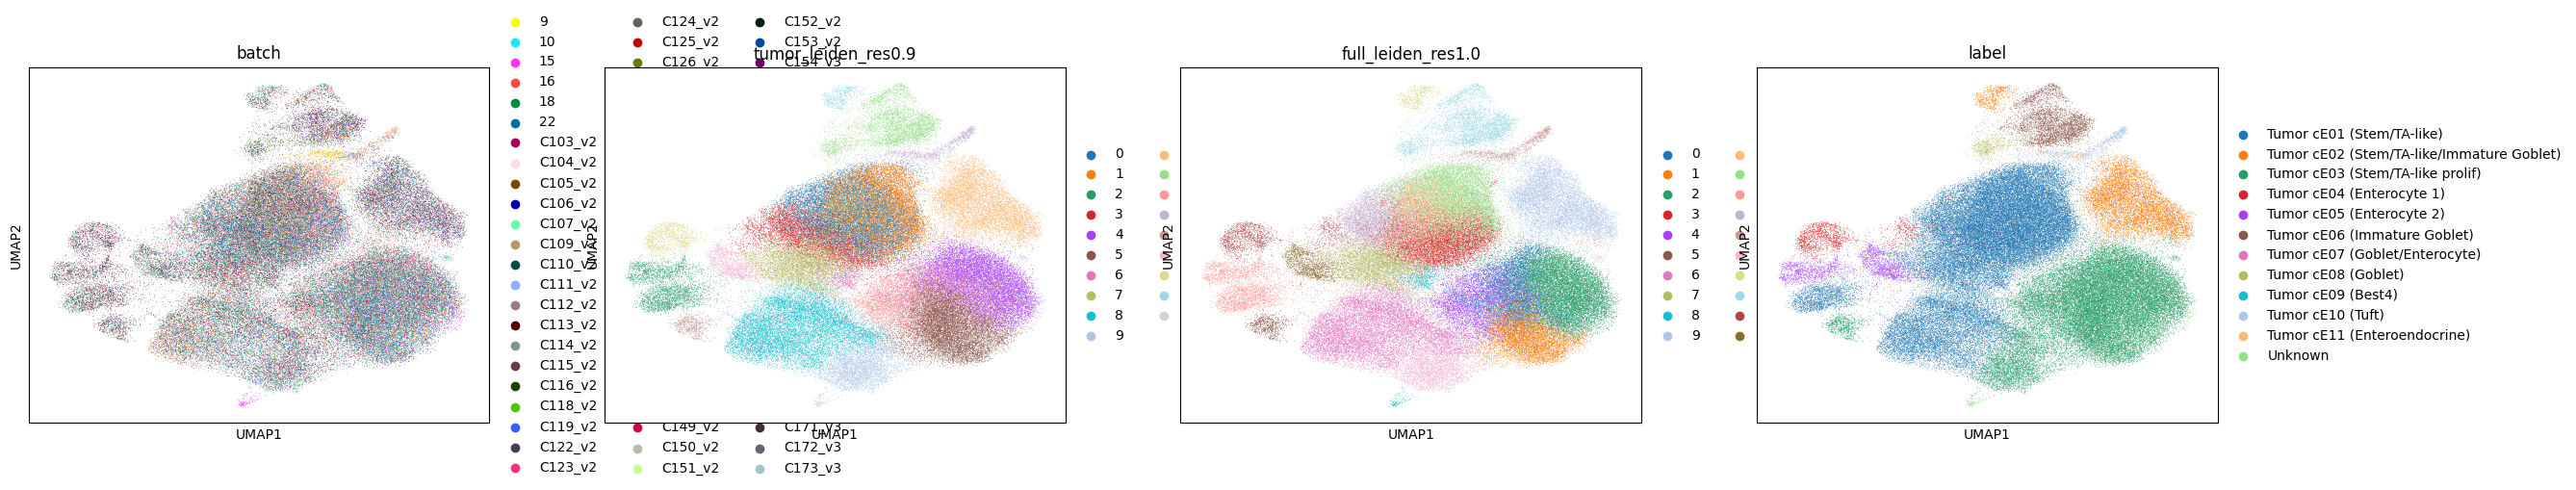

In [2]:
sc.pl.umap(adata, color=color)

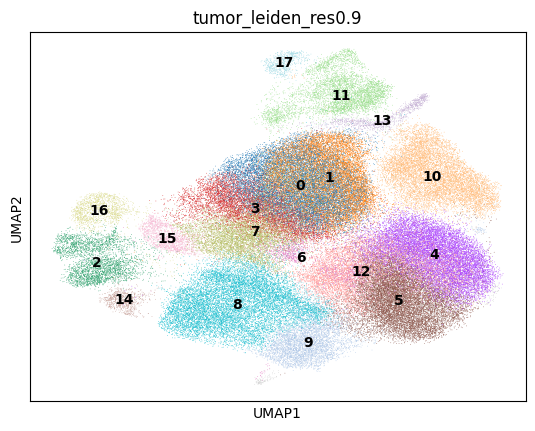

In [3]:
sc.pl.umap(adata, color=t_key, legend_loc="on data", na_in_legend=None)

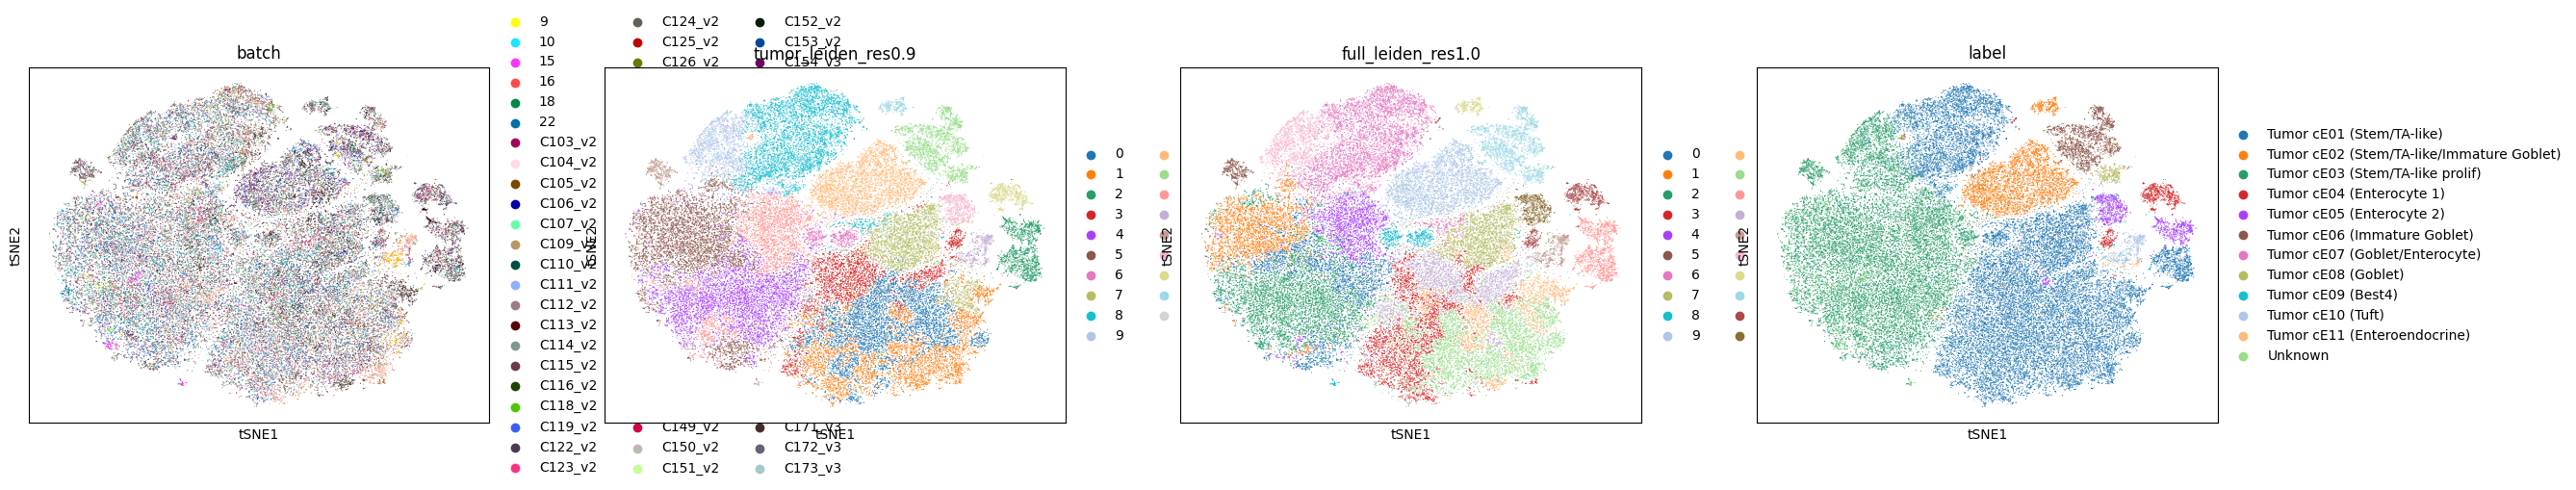

In [4]:
sc.tl.tsne(adata, use_rep="X_latent", random_state=0)
sc.pl.tsne(adata, color=color)

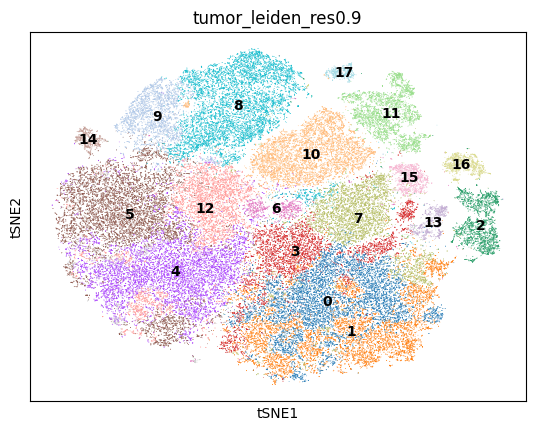

In [5]:
sc.pl.tsne(adata, color=t_key, legend_loc="on data", na_in_legend=None)

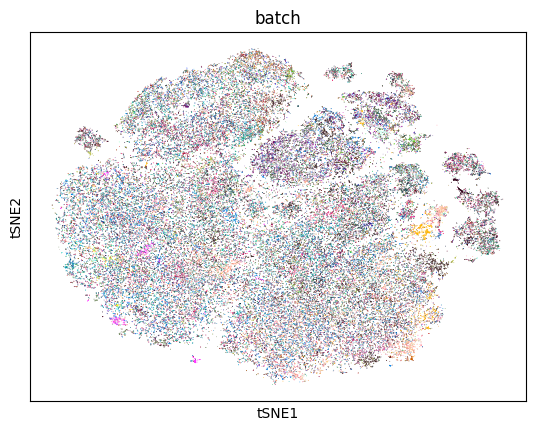

In [6]:
sc.pl.tsne(adata, color="batch", legend_loc=None)

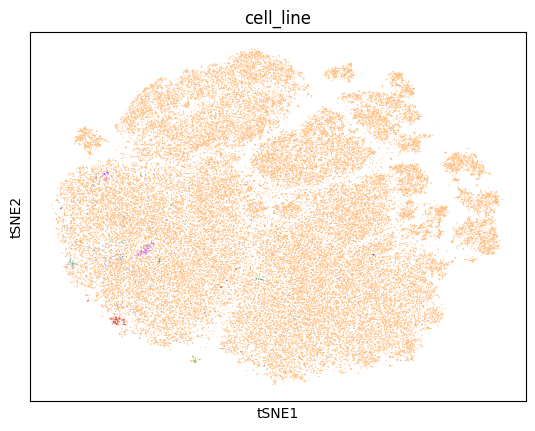

In [7]:
sc.pl.tsne(adata, color="cell_line", legend_loc=None)